# Facility Pooling vs Stovepipe

Overlapping mortality distributions.


In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_PATH = _root / "data_cluster/sobol_no_t2_fixed_pooling/results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]


Loaded 98304 runs


In [2]:
p1 = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 0)].sort_values("scenario").reset_index(drop=True)
p2 = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)].sort_values("scenario").reset_index(drop=True)
assert (p1["scenario"].values == p2["scenario"].values).all()

delta = p1["death_rate_T1_BCAS"].values - p2["death_rate_T1_BCAS"].values
print(f"fac: {len(p1)} runs, median mort = {p1['death_rate_T1_BCAS'].median():.3f}")
print(f"stove: {len(p2)} runs, median mort = {p2['death_rate_T1_BCAS'].median():.3f}")
print(f"Delta median: {np.median(delta):.4f}")
print(f"Delta > 0 (fac worse): {(delta > 0.01).sum()} / {len(delta)} ({(delta > 0.01).mean():.1%})")
print(f"Delta < 0 (fac better): {(delta < -0.01).sum()} / {len(delta)} ({(delta < -0.01).mean():.1%})")


fac: 24576 runs, median mort = 0.600
stove: 24576 runs, median mort = 0.600
Delta median: 0.0000
Delta > 0 (fac worse): 981 / 24576 (4.0%)
Delta < 0 (fac better): 539 / 24576 (2.2%)


## Mortality Distributions


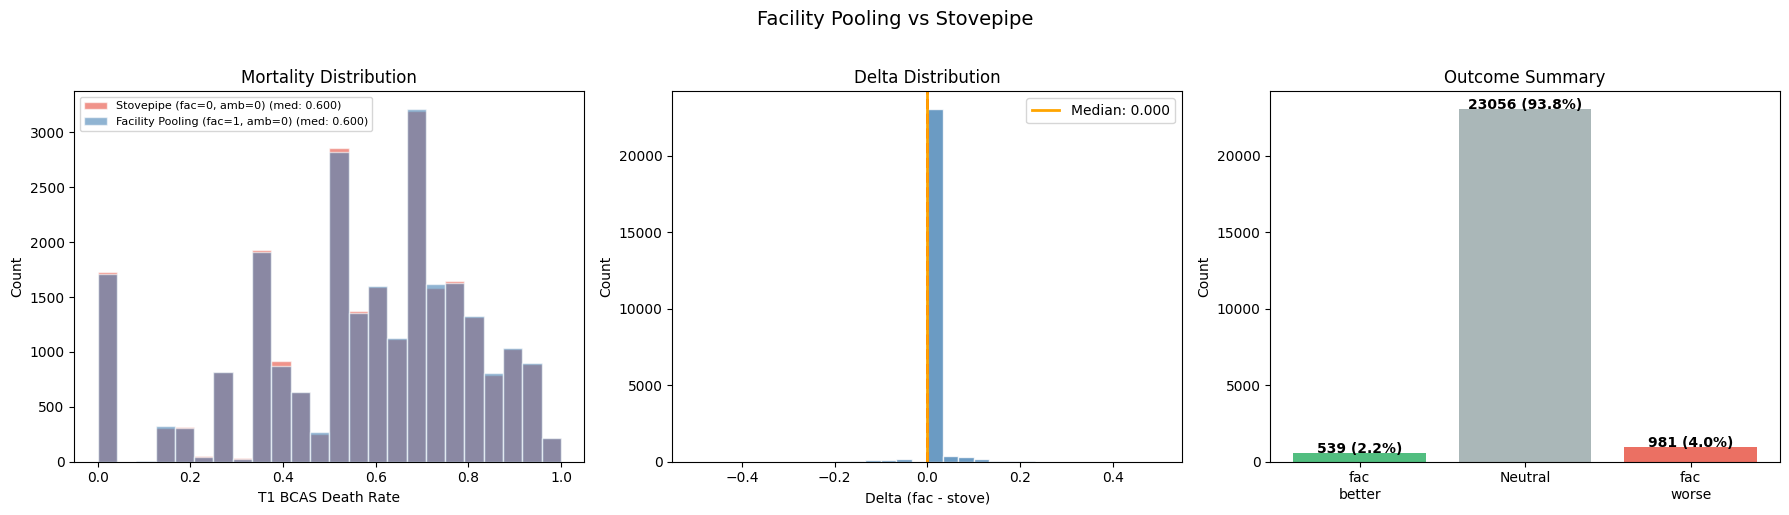

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

bins = np.linspace(0, 1, 25)
axes[0].hist(p2["death_rate_T1_BCAS"], bins=bins, alpha=0.6, color="#e74c3c", edgecolor="white", label=f"Stovepipe (fac=0, amb=0) (med: {p2['death_rate_T1_BCAS'].median():.3f})")
axes[0].hist(p1["death_rate_T1_BCAS"], bins=bins, alpha=0.6, color="steelblue", edgecolor="white", label=f"Facility Pooling (fac=1, amb=0) (med: {p1['death_rate_T1_BCAS'].median():.3f})")
axes[0].set_xlabel("T1 BCAS Death Rate")
axes[0].set_ylabel("Count")
axes[0].set_title("Mortality Distribution")
axes[0].legend(fontsize=8)

axes[1].hist(delta, bins=30, color="steelblue", alpha=0.8, edgecolor="white")
axes[1].axvline(0, color="red", linewidth=2, linestyle="--")
axes[1].axvline(np.median(delta), color="orange", linewidth=2, label=f"Median: {np.median(delta):.3f}")
axes[1].set_xlabel("Delta (fac - stove)")
axes[1].set_ylabel("Count")
axes[1].set_title("Delta Distribution")
axes[1].legend()

n_better = (delta < -0.01).sum()
n_neutral = ((delta >= -0.01) & (delta <= 0.01)).sum()
n_worse = (delta > 0.01).sum()
bars = axes[2].bar(["fac\nbetter", "Neutral", "fac\nworse"],
                    [n_better, n_neutral, n_worse],
                    color=["#27ae60", "#95a5a6", "#e74c3c"], alpha=0.8)
for bar, val in zip(bars, [n_better, n_neutral, n_worse]):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                 f"{val} ({val/len(delta):.1%})", ha="center", fontweight="bold")
axes[2].set_ylabel("Count")
axes[2].set_title("Outcome Summary")

fig.suptitle("Facility Pooling vs Stovepipe", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


## Stressed scenarios only (bcas >= 0.02)


Stressed: 20478 scenarios


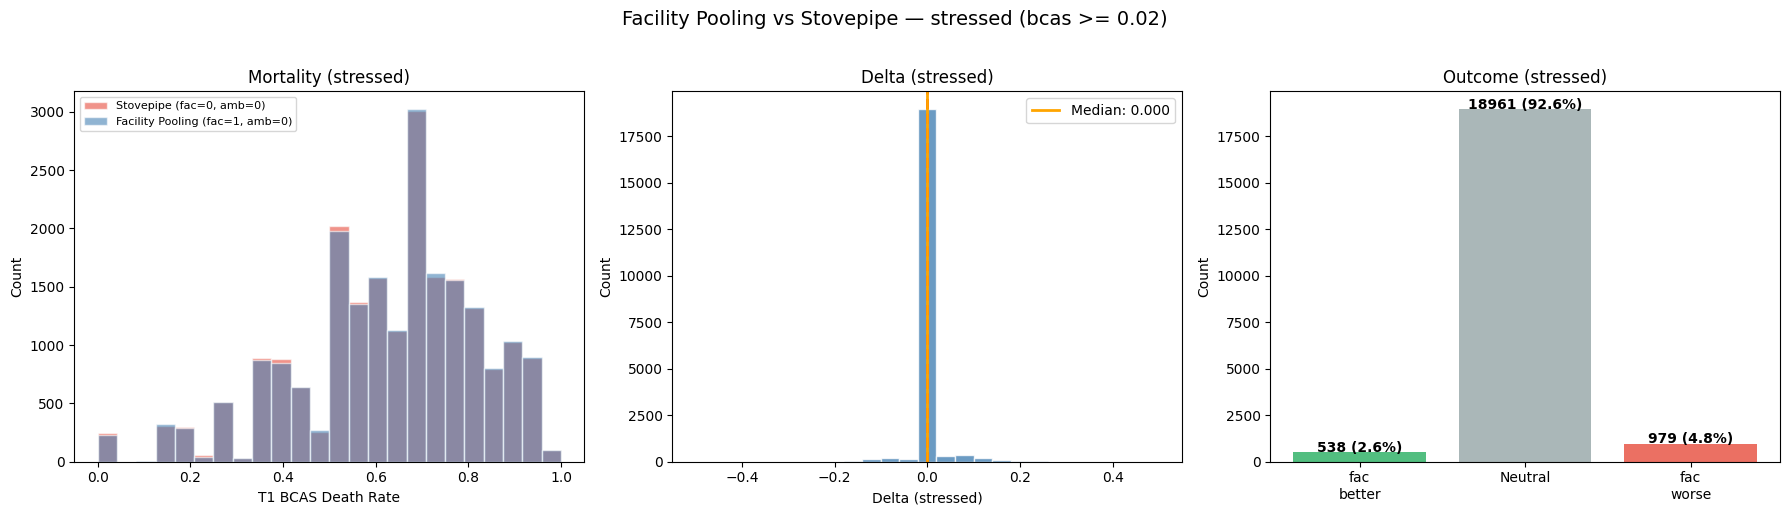

In [4]:
mask_s = p1["bcas_rate"] >= 0.02
p1s, p2s = p1[mask_s], p2[mask_s]
delta_s = p1s["death_rate_T1_BCAS"].values - p2s["death_rate_T1_BCAS"].values
print(f"Stressed: {len(p1s)} scenarios")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
bins = np.linspace(0, 1, 25)
axes[0].hist(p2s["death_rate_T1_BCAS"], bins=bins, alpha=0.6, color="#e74c3c", edgecolor="white", label=f"Stovepipe (fac=0, amb=0)")
axes[0].hist(p1s["death_rate_T1_BCAS"], bins=bins, alpha=0.6, color="steelblue", edgecolor="white", label=f"Facility Pooling (fac=1, amb=0)")
axes[0].set_xlabel("T1 BCAS Death Rate")
axes[0].set_ylabel("Count")
axes[0].set_title("Mortality (stressed)")
axes[0].legend(fontsize=8)

axes[1].hist(delta_s, bins=25, color="steelblue", alpha=0.8, edgecolor="white")
axes[1].axvline(0, color="red", linewidth=2, linestyle="--")
axes[1].axvline(np.median(delta_s), color="orange", linewidth=2, label=f"Median: {np.median(delta_s):.3f}")
axes[1].set_xlabel("Delta (stressed)")
axes[1].set_ylabel("Count")
axes[1].set_title("Delta (stressed)")
axes[1].legend()

n_b = (delta_s < -0.01).sum()
n_n = ((delta_s >= -0.01) & (delta_s <= 0.01)).sum()
n_w = (delta_s > 0.01).sum()
bars = axes[2].bar(["fac\nbetter", "Neutral", "fac\nworse"],
                    [n_b, n_n, n_w], color=["#27ae60", "#95a5a6", "#e74c3c"], alpha=0.8)
for bar, val in zip(bars, [n_b, n_n, n_w]):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 f"{val} ({val/len(delta_s):.1%})", ha="center", fontweight="bold")
axes[2].set_ylabel("Count")
axes[2].set_title("Outcome (stressed)")

fig.suptitle("Facility Pooling vs Stovepipe — stressed (bcas >= 0.02)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()
